# Tomato disease classification: fresh views and three paired seeds
## COMP 664 Topic 2 · 实际新增训练与可执行展示

**问题：** 强裁剪和颜色增强是否改善从 PlantVillage 干净叶片到 PlantDoc 田间图像的泛化？

这次已经实际训练 **6 个新模型**：种子 664、665、666，每个种子各训练普通增强和强增强模型 8 轮。每张图像每轮重新采样视图，全部 checkpoint 只用 PlantVillage 验证集选择。原始两固定视图实验单独保留为 legacy reference。

默认 **Run All** 读取真实训练输出，独立重算三种子的指标、波动、bootstrap 和逐类差距，并实际加载新权重做两张图片推理。默认不重新训练、不下载数据。后文提供完整训练函数与可选重新训练入口。

本文件已保存顺序执行输出，可以直接阅读。单独查看不需要原始数据；重新运行需要完整项目包及 Python 环境。新训练环境与普通展示环境分开记录，不能把 Notebook 的默认快速执行当成完整训练耗时。


## 1. 核心源文件

| 文件，位于 `project/` | 作用 |
| --- | --- |
| `prepare.py` | 九类映射、官方切分、叶片组划分和字节重复审计。 |
| `experiment_fresh.py` | 新增三种子真实训练：逐轮新视图、匹配初始化/顺序/预算、验证选择、全部选择锁定后测试。 |
| `summarize_fresh.py` | 核对训练记录并汇总种子均值、样本标准差及配对差值。 |
| `analyze.py` / `verify.py` | 从逐张预测计算指标、bootstrap，独立检查保存证据。 |
| `evaluate.py` / `demo.py` | 加载权重，对原始图片复算或现场演示。 |

`experiment.py` 保留原始训练实现，同时提供共享的模型结构。`paths.py` 处理 Windows 路径；`make_fresh_figures.py` 生成新报告图表。下面的真实训练代码与这些源文件保持一致。


## 2. 环境与开关

在 `project/` 按 `requirements-notebook.txt` 安装即可重跑默认展示。若要重复实际 GPU 训练，请使用 `requirements-train.txt` 的 PyTorch 2.7.1/torchvision 0.22.1 匹配环境；本次使用 cu128 与单张 RTX 5070 Ti Laptop GPU。


In [1]:
from pathlib import Path
import sys, os, json, hashlib, csv, random, re, time
from collections import defaultdict
import numpy as np
import pandas as pd
import torch
import torchvision
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as T
from torchvision.models import mobilenet_v3_small, MobileNet_V3_Small_Weights
from PIL import Image, ImageOps
from sklearn.metrics import accuracy_score, f1_score, recall_score, confusion_matrix
get_ipython().run_line_magic('matplotlib', 'inline')
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# Locate the bundled project from either the notebook or extracted package directory.
search_roots = [Path.cwd(), *list(Path.cwd().parents)[:3]]
candidates = [candidate for parent in search_roots for candidate in (parent, parent / 'project')]
PROJECT = next((p.resolve() for p in candidates
                if (p / 'experiment.py').is_file() and (p / 'results/manifest.csv').is_file()), None)
if PROJECT is None:
    raise FileNotFoundError('Unzip the full project and open the notebook from that package.')
if str(PROJECT) not in sys.path:
    sys.path.insert(0, str(PROJECT))
from paths import disk_path, canonical_path, storage_root

RESULTS = PROJECT / 'results'
DATA_DIR = PROJECT / 'data'
SCRATCH = PROJECT / '.build' / 'notebook'
FRESH = RESULTS / 'fresh_views'
SEEDS = [664, 665, 666]
RUN_RAW_PREPARATION = False
RUN_RETRAIN = False
RUN_FULL_REPLAY = False
DEVICE = 'cpu'
torch.set_num_threads(4)
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False})
print('Python', sys.version.split()[0], '| torch', torch.__version__, '| torchvision', torchvision.__version__)
print('Mode: three-seed saved-evidence recomputation + fresh-checkpoint example inference')

from concurrent.futures import ThreadPoolExecutor
from datetime import datetime, timezone
import math, shutil, platform
from torchvision.transforms import functional as F
from torchvision.transforms import InterpolationMode
from experiment import model, head, predict, transforms, SIZE, BATCH, EPOCHS
# Full training definitions below retain the script's provenance reference.
__file__ = str(PROJECT / 'experiment_fresh.py')
PROTOCOL = json.loads((FRESH / 'protocol.json').read_text(encoding='utf-8'))
COMPLETION = json.loads((FRESH / 'run_complete.json').read_text(encoding='utf-8'))
assert PROTOCOL['seeds'] == SEEDS and COMPLETION['status'] == 'PASS'


Python 3.12.14 | torch 2.5.1+cpu | torchvision 0.20.1+cpu
Mode: three-seed saved-evidence recomputation + fresh-checkpoint example inference


In [2]:
SOURCE_SHA256 = {'prepare.py': 'e1bc4169a8976201d24b4ed1d6a482b2440049cac11ee1354e232635a6d451f7', 'experiment.py': 'a017abc2f40563817965a6af97ab746cb0beedfa4376e80973d41204ab050124', 'experiment_fresh.py': '6bf570d954fc72e9d476e87dddd11bb41fce1d4904117612e04b3007f9a13b81', 'summarize_fresh.py': '13f35dffe1d9cc2960893bb3850300c112f63af9aa42e368e1f210cb9bd79519', 'analyze.py': 'd1e720140584a85f5d42d8c4ce41281dfbf98c707fa043b5898cf8b87a7d5a8d', 'evaluate.py': '421fcbeed962e9f80570b3fecbf8a8420ff1d4c7a335a4286b2fce263cc26d96', 'verify.py': '9c273862d8badab0418cc5558d815054fafae58e5a4a1fb382964dd4486250fd', 'paths.py': 'df3b2b9c19a4838049615fa67eb6283bc292a0297557dd0d3b9b117295236aae'}
for filename, expected in SOURCE_SHA256.items():
    assert hashlib.sha256((PROJECT / filename).read_bytes()).hexdigest() == expected, filename
print('Core source versions verified:', len(SOURCE_SHA256))
manifest = pd.read_csv(RESULTS / 'manifest.csv', keep_default_na=False)
legacy_predictions = pd.read_csv(RESULTS / 'predictions.csv')
predictions = legacy_predictions
print('New training:', COMPLETION['trained_models'], 'models;', COMPLETION['epochs_per_model'], 'epochs/model')
display(pd.DataFrame([COMPLETION]))


Core source versions verified: 8
New training: 6 models; 8 epochs/model


,status,completed_utc,trained_models,epochs_per_model,total_optimizer_steps,total_image_presentations,all_artifact_audits_passed
0,PASS,2026-11-11T01:40:00.615556+00:00,6,8,6048,577728,True


## 3. 数据映射与划分

只使用课程要求的九个共有番茄类别。PlantVillage 官方训练/测试名单保持隔离；只在原训练集的**已记录叶片组**内划分验证集。PlantDoc 的原 train/test 文件夹合并为外部测试集，完全不参与优化或 checkpoint 选择。

注意：mosaic virus 没有可用的训练叶片组 ID，所以验证集覆盖八类；训练和两个测试集仍覆盖九类。无 ID 图片留在训练集，不能据此声称所有未记录叶片也已验证独立。


In [3]:
LABELS = [
    ("Healthy", "healthy", "Tomato leaf"),
    ("Early blight", "Early_blight", "Tomato Early blight leaf"),
    ("Bacterial spot", "Bacterial_spot", "Tomato leaf bacterial spot"),
    ("Late blight", "Late_blight", "Tomato leaf late blight"),
    ("Mosaic virus", "Tomato_mosaic_virus", "Tomato leaf mosaic virus"),
    ("Yellow leaf curl", "Tomato_Yellow_Leaf_Curl_Virus", "Tomato leaf yellow virus"),
    ("Leaf mold", "Leaf_Mold", "Tomato mold leaf"),
    ("Septoria", "Septoria_leaf_spot", "Tomato Septoria leaf spot"),
    ("Spider mites", "Spider_mites Two-spotted_spider_mite", "Tomato two spotted spider mites leaf"),
]

def norm(s):
    return re.sub('[^a-z0-9]+', '', s.casefold())

def write_csv(path, rows):
    with open(path, 'w', newline='', encoding='utf-8') as f:
        w = csv.DictWriter(f, fieldnames=list(rows[0]))
        w.writeheader()
        w.writerows(rows)

class_names = [name for name, _, _ in LABELS]
class_ids = list(range(len(LABELS)))
mapping = pd.read_csv(RESULTS / 'class_mapping.csv')
display(mapping)


,label,category,PlantVillage,PlantDoc
0,0,Healthy,Tomato___healthy,Tomato leaf
1,1,Early blight,Tomato___Early_blight,Tomato Early blight leaf
2,2,Bacterial spot,Tomato___Bacterial_spot,Tomato leaf bacterial spot
3,3,Late blight,Tomato___Late_blight,Tomato leaf late blight
4,4,Mosaic virus,Tomato___Tomato_mosaic_virus,Tomato leaf mosaic virus
5,5,Yellow leaf curl,Tomato___Tomato_Yellow_Leaf_Curl_Virus,Tomato leaf yellow virus
6,6,Leaf mold,Tomato___Leaf_Mold,Tomato mold leaf
7,7,Septoria,Tomato___Septoria_leaf_spot,Tomato Septoria leaf spot
8,8,Spider mites,Tomato___Spider_mites Two-spotted_spider_mite,Tomato two spotted spider mites leaf


In [4]:
def prepare(root, out):
    root=storage_root(root)
    pv = root / 'PlantVillage-Dataset-master'
    pd = root / 'PlantDoc-Dataset-master'
    leafmap = json.loads((root / 'leaf-map.json').read_text(encoding='utf-8'))
    source = {norm('Tomato___'+v): i for i, (_, v, _) in enumerate(LABELS)}
    field = {norm(v): i for i, (_, _, v) in enumerate(LABELS)}
    rows, excluded = [], []
    def add(path, domain, upstream, split, k, group=''):
        rows.append(dict(path=canonical_path(path,root), domain=domain,
                         upstream_split=upstream, split=split, label=k, category=LABELS[k][0],
                         leaf_group=group, sha256=hashlib.sha256(path.read_bytes()).hexdigest()))
    for split in ('train', 'test'):
        for line in (root / f'color_{split}.txt').read_text(encoding='utf-8').splitlines():
            path = disk_path(root, 'PlantVillage-Dataset-master/'+line.strip())
            folder = path.parent.name
            k = source.get(norm(folder))
            if k is None:
                continue
            key = path.stem.split('___')[-1].strip().lower()
            ids = [g for g in leafmap.get(key, []) if g.startswith(folder+':::')]
            if len(ids) > 1:
                raise ValueError(f'Ambiguous leaf id: {path}')
            add(path, 'PlantVillage', split, 'pv_'+split, k, ids[0] if ids else '')
    # Only documented leaf IDs can enter validation. Unknown IDs stay in training.
    rng = random.Random(664)
    for k in range(len(LABELS)):
        groups = sorted({r['leaf_group'] for r in rows if r['label']==k
                         and r['split']=='pv_train' and r['leaf_group']})
        rng.shuffle(groups)
        holdout = set(groups[:round(0.15*len(groups))])
        for r in rows:
            if r['split']=='pv_train' and r['leaf_group'] in holdout:
                r['split']='pv_val'
    for split in ('train','test'):
        for path in sorted((pd / split).glob('*/*'),key=lambda p:canonical_path(p,root)):
            k = field.get(norm(path.parent.name))
            if k is not None and path.is_file() and path.suffix.lower() in {'.jpg','.jpeg','.png','.bmp','.webp','.gif','.jfif','.tif','.tiff'}:
                add(path,'PlantDoc',split,'pd_test',k)
    by_hash = defaultdict(list)
    for r in rows:
        by_hash[r['sha256']].append(r)
    remove = set()
    for batch in by_hash.values():
        if len({r['split'] for r in batch})>1:
            priority = {'pv_train':0, 'pv_val':1, 'pv_test':2, 'pd_test':3}
            high = max(priority[r['split']] for r in batch)
            for r in batch:
                if priority[r['split']] < high:
                    excluded.append(dict(**r, reason='identical bytes in a held-out split'))
                    remove.add(r['path'])
        if batch[0]['domain']=='PlantDoc' and len(batch)>1:
            conflict=len({r['label'] for r in batch})>1
            for r in (batch if conflict else sorted(batch,key=lambda x:x['path'])[1:]):
                excluded.append(dict(**r, reason='conflicting labels' if conflict else 'exact duplicate'))
                remove.add(r['path'])
    rows=sorted((r for r in rows if r['path'] not in remove),key=lambda r:r['path'])
    seen={}
    for r in rows:
        g=r['leaf_group']
        if g and seen.setdefault(g,r['split']) != r['split']:
            raise ValueError(f'Leaf {g} crosses a split')
    for split in ('pv_train','pv_test','pd_test'):
        assert len({r['label'] for r in rows if r['split']==split})==9
    assert len({r['path'] for r in rows})==len(rows)
    out.mkdir(parents=True, exist_ok=True)
    write_csv(out/'manifest.csv',rows)
    if excluded:
        write_csv(out/'exclusions.csv',excluded)
    write_csv(out/'class_mapping.csv',[dict(label=i,category=name,PlantVillage='Tomato___'+pvname,PlantDoc=pdname)
                                        for i,(name,pvname,pdname) in enumerate(LABELS)])
    from collections import Counter
    print(Counter(r['split'] for r in rows), 'exclusions',len(excluded))


上面的 `prepare()` 是真实数据准备函数，此处定义它并不会触发下载。接下来直接检查随包的已处理清单。


In [5]:
counts = pd.crosstab(manifest['label'], manifest['split']).reindex(
    index=class_ids, columns=['pv_train', 'pv_val', 'pv_test', 'pd_test'], fill_value=0)
counts.index = class_names
counts.loc['TOTAL'] = counts.sum()
display(counts)

known = manifest.loc[manifest['leaf_group'].ne('')]
assert known.groupby('leaf_group')['split'].nunique().max() == 1
assert manifest.groupby('sha256')['split'].nunique().max() == 1
field = manifest.loc[manifest['split'].eq('pd_test')]
assert field['sha256'].is_unique
assert len(manifest) == 17493 and len(predictions) == 8186
excluded = pd.read_csv(RESULTS / 'exclusions.csv')
display(excluded.groupby('reason').size().rename('removed_entries').to_frame())
print('PASS: documented leaf groups and exact hashes do not cross splits.')
print('Exact-byte checks do not establish independence of near-duplicates or undocumented leaves.')


split,pv_train,pv_val,pv_test,pd_test
Healthy,1143,116,330,63
Early blight,669,116,215,88
Bacterial spot,1439,252,436,109
Late blight,1419,112,375,111
Mosaic virus,307,0,66,54
Yellow leaf curl,3933,324,1100,75
Leaf mold,664,116,172,91
Septoria,1310,124,337,149
Spider mites,1152,204,320,2
TOTAL,12036,1364,3351,742


,removed_entries
reason,
conflicting labels,2
exact duplicate,2
identical bytes in a held-out split,5


PASS: documented leaf groups and exact hashes do not cross splits.
Exact-byte checks do not establish independence of near-duplicates or undocumented leaves.


In [6]:
if RUN_RAW_PREPARATION:
    from download import get_data
    get_data(DATA_DIR)
    prepare(DATA_DIR, SCRATCH / 'reconstructed')
    for name in ['manifest.csv','exclusions.csv','class_mapping.csv']:
        assert (SCRATCH / 'reconstructed' / name).read_bytes() == (RESULTS / name).read_bytes()
else:
    print('Raw-data download/preparation skipped; this run uses the unchanged verified manifest.')


Raw-data download/preparation skipped; this run uses the unchanged verified manifest.


## 4. 从两个固定视图改为每轮新视图

只缓存确定性的 EXIF 校正、RGB 转换和 128 × 128 resize；**不缓存随机增强视图**。每个训练样本的局部随机数由 `(seed, epoch, image_index)` 决定，因此每轮重新采样，同时不受线程调度影响。

普通训练只有翻转/不翻转两种结果，重新采样仍可能重复；强增强会每轮重新采样裁剪和颜色。两组内的图像顺序与初始化完全匹配。模型结构和最后两块训练方式保持原方案。


In [7]:
def crop_parameters(rng,width,height):
    area=width*height
    for _ in range(10):
        target=rng.uniform(.55,1.)*area
        aspect=math.exp(rng.uniform(math.log(.8),math.log(1.25)))
        w=round(math.sqrt(target*aspect));h=round(math.sqrt(target/aspect))
        if 0<w<=width and 0<h<=height:
            return rng.randint(0,height-h),rng.randint(0,width-w),h,w
    # Same central fallback rule as torchvision RandomResizedCrop.
    ratio=width/height
    if ratio<.8:
        w=width;h=round(w/.8)
    elif ratio>1.25:
        h=height;w=round(h*1.25)
    else:
        w=width;h=height
    return (height-h)//2,(width-w)//2,h,w

def fresh_transform(rgb,condition,seed,epoch,index):
    """Local RNGs make views reproducible across threads, with new draws each epoch."""
    rng=random.Random(int(seed)*1_000_000_000+int(epoch)*100_000+int(index))
    im=Image.fromarray(np.asarray(rgb,dtype=np.uint8))
    if condition=='strong':
        top,left,height,width=crop_parameters(rng,*im.size)
        im=F.resized_crop(im,top,left,height,width,[SIZE,SIZE],InterpolationMode.BILINEAR,antialias=True)
        factors=[rng.uniform(.65,1.35),rng.uniform(.65,1.35),rng.uniform(.65,1.35),rng.uniform(-.07,.07)]
        order=list(range(4));rng.shuffle(order)
        functions=[F.adjust_brightness,F.adjust_contrast,F.adjust_saturation,F.adjust_hue]
        for k in order:
            im=functions[k](im,factors[k])
    elif condition!='ordinary':
        raise ValueError('Unknown condition')
    if rng.random()<.5:
        im=F.hflip(im)
    return F.normalize(F.to_tensor(im),[.485,.456,.406],[.229,.224,.225])


In [8]:
# A targeted check on the requirement added in this extension.
rgb = np.random.default_rng(664).integers(0,256,(128,128,3),dtype=np.uint8)
a = fresh_transform(rgb, 'strong', 664, 0, 17)
b = fresh_transform(rgb, 'strong', 664, 0, 17)
c = fresh_transform(rgb, 'strong', 664, 1, 17)
assert torch.equal(a,b) and not torch.equal(a,c)
with ThreadPoolExecutor(max_workers=4) as pool:
    parallel = list(pool.map(lambda i:fresh_transform(rgb,'strong',664,2,i),range(8)))
serial = [fresh_transform(rgb,'strong',664,2,i) for i in range(8)]
assert all(torch.equal(a,b) for a,b in zip(serial,parallel))
print('PASS: reproducible views, fresh epochs, and thread-independent randomness.')


PASS: reproducible views, fresh epochs, and thread-independent randomness.


### 实际模型、训练函数与可选重训

下列单元包含脚本中的真实实现。较长的缓存/日志辅助函数可折叠阅读。定义函数不会启动训练；只有将开关改为 True 才运行。新权重来自本次单独执行的六模型训练任务，其完成记录已在上文显示。

所有六个 checkpoint 选定并记录哈希后，才统一读取、评估两个测试集。使用所有种子的结果，不根据田间分数挑选最好种子。


In [9]:
def model(pretrained):
    net=mobilenet_v3_small(weights=MobileNet_V3_Small_Weights.DEFAULT if pretrained else None)
    net.classifier[-1]=nn.Linear(net.classifier[-1].in_features,len(LABELS))
    return net

def head(net, x):
    x=net.features[-2:](x)
    return net.classifier(net.avgpool(x).flatten(1))

@torch.inference_mode()
def predict(net,feats,device):
    net.eval()
    return torch.cat([head(net,x.to(device=device,dtype=torch.float32,memory_format=torch.channels_last)).softmax(1).cpu()
                      for x in feats.split(BATCH)])


In [10]:
def utc():
    return datetime.now(timezone.utc).isoformat()

def digest_state(state):
    h=hashlib.sha256()
    for name,value in sorted(state.items()):
        h.update(name.encode())
        h.update(value.detach().cpu().contiguous().numpy().tobytes())
    return h.hexdigest()

def write_json(path,value):
    path.parent.mkdir(parents=True,exist_ok=True)
    temp=path.with_suffix(path.suffix+'.part')
    temp.write_text(json.dumps(value,indent=2)+'\n',encoding='utf-8')
    temp.replace(path)

def event(out,kind,**values):
    row=dict(time_utc=utc(),event=kind,**values)
    with (out/'events.jsonl').open('a',encoding='utf-8') as f:
        f.write(json.dumps(row)+'\n')
    print(json.dumps(row),flush=True)

def prepare_pixels(rows,data,cache,workers,out,split_name):
    """Cache only deterministic RGB resize. Random training views are never cached."""
    descriptor=json.dumps(dict(paths=[(r['path'],r['sha256']) for r in rows],size=SIZE,
                               interpolation='PIL bilinear',exif=True),sort_keys=True).encode()
    key=hashlib.sha256(descriptor).hexdigest()
    cache.mkdir(parents=True,exist_ok=True)
    pixel_path=cache/(split_name+'-'+key[:16]+'.npy')
    receipt=pixel_path.with_suffix('.json')
    if receipt.exists() and pixel_path.exists():
        record=json.loads(receipt.read_text(encoding='utf-8'))
        if record['descriptor_sha256']!=key:
            raise ValueError('Pixel-cache descriptor mismatch')
        event(out,'pixel_cache_reused',split=split_name,images=len(rows))
        return np.load(pixel_path,mmap_mode='r')
    pixels=np.lib.format.open_memmap(pixel_path,mode='w+',dtype=np.uint8,shape=(len(rows),SIZE,SIZE,3))
    def decode(item):
        i,r=item
        raw=disk_path(data,r['path']).read_bytes()
        if hashlib.sha256(raw).hexdigest()!=r['sha256']:
            raise ValueError('Raw image hash mismatch: '+r['path'])
        with Image.open(io.BytesIO(raw)) as im:
            rgb=ImageOps.exif_transpose(im).convert('RGB')
            rgb=F.resize(rgb,[SIZE,SIZE],InterpolationMode.BILINEAR,antialias=True)
            return i,np.asarray(rgb)
    with ThreadPoolExecutor(max_workers=workers) as pool:
        for start in range(0,len(rows),256):
            items=list(enumerate(rows[start:start+256],start=start))
            for i,rgb in pool.map(decode,items):
                pixels[i]=rgb
            if start%2048==0:
                event(out,'pixel_cache_progress',split=split_name,completed=min(start+256,len(rows)),total=len(rows))
    pixels.flush();del pixels
    write_json(receipt,dict(descriptor_sha256=key,images=len(rows),raw_sha256_verified=True,created_utc=utc()))
    event(out,'pixel_cache_complete',split=split_name,images=len(rows),all_raw_hashes_verified=True)
    return np.load(pixel_path,mmap_mode='r')

@torch.inference_mode()
def encode_pixels(prefix,pixels,device):
    blocks=[]
    mean=torch.tensor([.485,.456,.406],device=device).view(1,3,1,1)
    std=torch.tensor([.229,.224,.225],device=device).view(1,3,1,1)
    for start in range(0,len(pixels),BATCH):
        x=torch.from_numpy(np.array(pixels[start:start+BATCH],copy=True)).permute(0,3,1,2)
        x=x.to(device=device,dtype=torch.float32,memory_format=torch.channels_last)/255.
        x=(x-mean)/std
        blocks.append(prefix(x).cpu().half())
    return torch.cat(blocks)


In [11]:
def run_fresh(data,manifest_path,out,cache,device,seeds,workers=4,threads=4):
    out.mkdir(parents=True,exist_ok=True)
    torch.set_num_threads(threads)
    torch.use_deterministic_algorithms(True)
    torch.backends.cudnn.benchmark=False
    torch.backends.cudnn.deterministic=True
    torch.backends.cuda.matmul.allow_tf32=False
    torch.backends.cudnn.allow_tf32=False
    with manifest_path.open(encoding='utf-8',newline='') as f:
        rows=list(csv.DictReader(f))
    sets={split:[r for r in rows if r['split']==split] for split in ['pv_train','pv_val','pv_test','pd_test']}
    script_hash=hashlib.sha256(Path(__file__).read_bytes()).hexdigest()
    plan=dict(protocol='fresh_views_v1',seeds=seeds,conditions=['ordinary','strong'],epochs=EPOCHS,batch_size=BATCH,
        input_size=SIZE,initialization='ImageNet MobileNetV3-Small; identical within seed',
        trainable='last inverted residual block, final convolution, classifier',
        optimizer='AdamW',learning_rate=.0005,weight_decay=.0001,
        fresh_view='independent per-image local Python RNG each epoch; PIL transforms',
        random_seed_formula='seed*1000000000 + epoch*100000 + image_index',
        ordinary='PIL resize 128, p=0.5 horizontal flip, ImageNet normalization',
        strong='same plus crop area .55-1, log-uniform ratio .8-1.25 and jitter .35/.35/.35/.07',
        prefix='eval mode, frozen weights, fresh forward pass each batch; float16 activations then float32 trainable blocks',
        checkpoint_selection='first maximum eight-supported-class source-validation macro-F1',
        split_selection='original fixed split; no seed-based resplitting',
        external_evaluation='only after all six checkpoints finalized; no field-based selection',
        manifest_sha256=hashlib.sha256(manifest_path.read_bytes()).hexdigest(),script_sha256=script_hash,
        torch=torch.__version__,torchvision=torchvision.__version__,python=platform.python_version(),
        hardware=torch.cuda.get_device_name(0) if device.startswith('cuda') else platform.processor(),
        device=device,deterministic_algorithms=True,tf32=False)
    plan_file=out/'protocol.json'
    if plan_file.exists():
        if json.loads(plan_file.read_text(encoding='utf-8'))!=plan:
            raise ValueError('Output contains a different protocol. Use a new output directory.')
    else:
        write_json(plan_file,plan)
    event(out,'run_started',seeds=seeds,device=device,script_sha256=script_hash)
    train_pixels=prepare_pixels(sets['pv_train'],data,cache,workers,out,'pv_train')
    val_pixels=prepare_pixels(sets['pv_val'],data,cache,workers,out,'pv_val')
    y_train=torch.tensor([int(r['label']) for r in sets['pv_train']],device=device)
    y_val=np.array([int(r['label']) for r in sets['pv_val']])
    torch.manual_seed(seeds[0])
    base=model(True).to(device=device,memory_format=torch.channels_last)
    prefix=base.features[:-2].eval()
    prefix.requires_grad_(False)
    prefix_hash=digest_state(prefix.state_dict())
    val_features=encode_pixels(prefix,val_pixels,device)
    for seed in seeds:
        seed_out=out/f'seed_{seed}';seed_out.mkdir(exist_ok=True)
        shutil.copy2(manifest_path,seed_out/'manifest.csv')
        for name in ['class_mapping.csv','exclusions.csv']:
            source=manifest_path.parent/name
            if source.exists():shutil.copy2(source,seed_out/name)
        torch.manual_seed(seed)
        net=model(True).to(device=device,memory_format=torch.channels_last)
        initial={k:v.detach().cpu().clone() for k,v in net.state_dict().items()}
        initial_hash=digest_state(initial)
        del net
        for condition in ['ordinary','strong']:
            done=seed_out/f'{condition}_training_complete.json'
            if done.exists():
                event(out,'training_already_complete',seed=seed,condition=condition)
                continue
            net=model(False).to(device=device,memory_format=torch.channels_last)
            net.load_state_dict(initial)
            net.features[:-2].requires_grad_(False)
            opt=torch.optim.AdamW([p for p in net.parameters() if p.requires_grad],lr=.0005,weight_decay=.0001)
            history_file=seed_out/f'history_{condition}.csv'
            records=[];best=-1.;start_epoch=0
            resume_path=cache/f'resume_{seed}_{condition}.pt'
            if resume_path.exists():
                resume=torch.load(resume_path,map_location=device,weights_only=True)
                if resume['script_sha256']!=script_hash:raise ValueError('Resume source mismatch')
                net.load_state_dict(resume['model']);opt.load_state_dict(resume['optimizer'])
                records=resume['records'];best=resume['best'];start_epoch=resume['epoch']
                torch.set_rng_state(resume['cpu_rng'].cpu())
                if device.startswith('cuda'):torch.cuda.set_rng_state(resume['cuda_rng'].cpu())
                del resume
            else:
                torch.manual_seed(seed)
                if device.startswith('cuda'):torch.cuda.manual_seed_all(seed)
            event(out,'condition_started',seed=seed,condition=condition,initial_state_sha256=initial_hash,start_epoch=start_epoch)
            condition_start=time.monotonic()
            with ThreadPoolExecutor(max_workers=workers) as pool:
                for epoch in range(start_epoch,EPOCHS):
                    epoch_start=time.monotonic()
                    net.train();net.features[:-2].eval()
                    order=torch.randperm(len(y_train),generator=torch.Generator().manual_seed(seed+epoch*1_000_000))
                    order_hash=hashlib.sha256(order.numpy().tobytes()).hexdigest()
                    loss_sum=0.;step=0
                    for ix in order.split(BATCH):
                        indices=ix.tolist()
                        def augment(i):
                            return fresh_transform(train_pixels[i],condition,seed,epoch,i)
                        x=torch.stack(list(pool.map(augment,indices))).to(device=device,memory_format=torch.channels_last)
                        with torch.no_grad():
                            features=net.features[:-2](x).half().float()
                        logits=head(net,features)
                        loss=nn.functional.cross_entropy(logits,y_train[ix.to(device)])
                        if not torch.isfinite(loss):raise ValueError('Non-finite training loss')
                        opt.zero_grad(set_to_none=True);loss.backward();opt.step()
                        loss_sum+=float(loss.detach())*len(ix);step+=1
                    probs=predict(net,val_features,device).numpy()
                    pred=probs.argmax(1)
                    score=float(f1_score(y_val,pred,labels=np.unique(y_val),average='macro',zero_division=0))
                    row=dict(condition=condition,epoch=epoch+1,train_loss=loss_sum/len(y_train),
                        val_accuracy=float((pred==y_val).mean()),val_supported_macro_f1=score,
                        seconds=round(time.monotonic()-epoch_start,3),optimizer_steps=step,
                        sample_order_sha256=order_hash,augmentation_epoch=epoch)
                    records.append(row)
                    if score>best:
                        best=score
                        checkpoint=dict(model={k:v.detach().cpu().clone() for k,v in net.state_dict().items()},
                            condition=condition,epoch=epoch+1,size=SIZE,labels=[x[0] for x in LABELS],seed=seed,
                            protocol='fresh_views_v1',initial_state_sha256=initial_hash,
                            source_prefix_sha256=prefix_hash,script_sha256=script_hash)
                        torch.save(checkpoint,seed_out/f'{condition}.pt')
                        del checkpoint
                    write_csv(history_file,records)
                    resume=dict(model=net.state_dict(),optimizer=opt.state_dict(),records=records,best=best,
                        epoch=epoch+1,cpu_rng=torch.get_rng_state(),script_sha256=script_hash)
                    if device.startswith('cuda'):resume['cuda_rng']=torch.cuda.get_rng_state()
                    temp=resume_path.with_suffix('.part');torch.save(resume,temp);temp.replace(resume_path)
                    event(out,'epoch_complete',seed=seed,**row)
            assert digest_state(net.features[:-2].state_dict())==prefix_hash
            final_hash=digest_state(net.state_dict())
            assert final_hash!=initial_hash
            write_json(done,dict(seed=seed,condition=condition,epochs=EPOCHS,optimizer_steps=sum(r['optimizer_steps'] for r in records),
                image_presentations=len(y_train)*EPOCHS,initial_state_sha256=initial_hash,final_state_sha256=final_hash,
                frozen_prefix_unchanged=True,training_seconds=round(time.monotonic()-condition_start,3),completed_utc=utc()))
            del net,opt
        combined=[]
        for condition in ['ordinary','strong']:
            with (seed_out/f'history_{condition}.csv').open(encoding='utf-8',newline='') as f:
                combined.extend(csv.DictReader(f))
        write_csv(seed_out/'history.csv',combined)
    # This milestone is written before any test images are read or test predictions produced.
    write_json(out/'selection_locked.json',dict(time_utc=utc(),seeds=seeds,all_conditions_complete=True,
        checkpoint_sha256={f'{seed}/{condition}':hashlib.sha256((out/f'seed_{seed}'/f'{condition}.pt').read_bytes()).hexdigest()
                           for seed in seeds for condition in ['ordinary','strong']}))
    event(out,'all_checkpoints_locked_before_test_evaluation')
    for split in ['pv_test','pd_test']:
        pixels=prepare_pixels(sets[split],data,cache,workers,out,split)
        feats=encode_pixels(prefix,pixels,device)
        for seed in seeds:
            seed_out=out/f'seed_{seed}'
            predictions=[]
            for condition in ['ordinary','strong']:
                checkpoint=torch.load(seed_out/f'{condition}.pt',map_location='cpu',weights_only=True)
                net=model(False).to(device=device,memory_format=torch.channels_last)
                net.load_state_dict(checkpoint['model']);net.eval()
                assert digest_state(net.features[:-2].state_dict())==prefix_hash
                for r,p in zip(sets[split],predict(net,feats,device).numpy()):
                    predictions.append(dict(path=r['path'],split=split,condition=condition,y_true=r['label'],y_pred=int(p.argmax()),
                        confidence=float(p.max()),**{f'p_{k}':float(v) for k,v in enumerate(p)}))
                del net,checkpoint
            write_csv(seed_out/f'predictions_{split}.csv',predictions)
            event(out,'test_predictions_saved',seed=seed,split=split,predictions=len(predictions))
        del pixels,feats
    for seed in seeds:
        seed_out=out/f'seed_{seed}'
        combined=[]
        for split in ['pv_test','pd_test']:
            with (seed_out/f'predictions_{split}.csv').open(encoding='utf-8',newline='') as f:
                combined.extend(csv.DictReader(f))
        write_csv(seed_out/'predictions.csv',combined)
        from analyze import analyze
        from verify import audit
        analyze(seed_out)
        write_json(seed_out/'artifact_verification.json',audit(seed_out))
    event(out,'run_complete',seeds=seeds)
    write_json(out/'run_complete.json',dict(status='PASS',completed_utc=utc(),trained_models=2*len(seeds),
        epochs_per_model=EPOCHS,total_optimizer_steps=2*len(seeds)*math.ceil(len(y_train)/BATCH)*EPOCHS,
        total_image_presentations=2*len(seeds)*len(y_train)*EPOCHS,all_artifact_audits_passed=True))


In [12]:
if RUN_RETRAIN:
    if not (DATA_DIR / 'leaf-map.json').is_file():
        raise FileNotFoundError('Prepare the pinned raw data or configure DATA_DIR first.')
    os.environ.setdefault('CUBLAS_WORKSPACE_CONFIG', ':4096:8')
    run_fresh(DATA_DIR, RESULTS / 'manifest.csv', SCRATCH / 'fresh_retrain',
              SCRATCH / 'pixel_cache', DEVICE, SEEDS, workers=4, threads=4)
else:
    print('Retraining skipped in Notebook execution. The six saved models were genuinely trained in the separate run.')


Retraining skipped in Notebook execution. The six saved models were genuinely trained in the separate run.


## 5. 真实训练历史与匹配审计

48 个 epoch、6,048 个优化步骤、577,728 次图像呈现。每个种子内检查两组的初始化哈希和每轮样本顺序一致；模型冻结前缀保持不变。验证集仍只有八个支持类别，这是保留的局限。


,seed,condition,selected_epoch,optimizer_steps,image_presentations
0,664,ordinary,8,1008,96288
1,664,strong,8,1008,96288
2,665,ordinary,8,1008,96288
3,665,strong,8,1008,96288
4,666,ordinary,6,1008,96288
5,666,strong,5,1008,96288


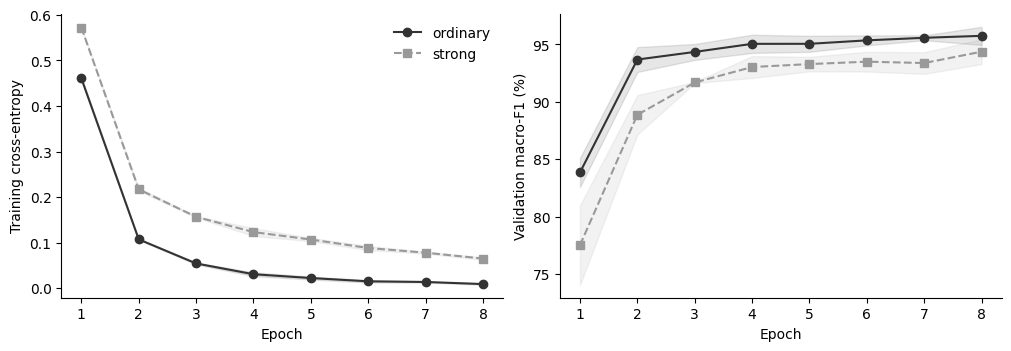

In [13]:
history = pd.read_csv(FRESH / 'all_history.csv')
training_audit = pd.read_csv(FRESH / 'training_audit.csv')
for seed in SEEDS:
    h = history.loc[history['seed'].eq(seed)]
    a = h.loc[h['condition'].eq('ordinary')].sort_values('epoch')
    b = h.loc[h['condition'].eq('strong')].sort_values('epoch')
    assert a['sample_order_sha256'].tolist() == b['sample_order_sha256'].tolist()
    assert a['optimizer_steps'].sum() == b['optimizer_steps'].sum() == 1008
    records=[json.loads((FRESH/f'seed_{seed}'/f'{c}_training_complete.json').read_text()) for c in ['ordinary','strong']]
    assert records[0]['initial_state_sha256'] == records[1]['initial_state_sha256']
assert len(history) == 48
assert training_audit['frozen_prefix_unchanged'].all()
display(training_audit[['seed','condition','selected_epoch','optimizer_steps','image_presentations']])
fig, axes = plt.subplots(1,2,figsize=(10,3.4),layout='constrained')
for condition,color in [('ordinary','#333333'),('strong','#999999')]:
    h=history.loc[history['condition'].eq(condition)]
    for ax,metric,label in zip(axes,['train_loss','val_supported_macro_f1'],['Training cross-entropy','Validation macro-F1 (%)']):
        scale=100 if metric=='val_supported_macro_f1' else 1
        stats=h.groupby('epoch')[metric].agg(['mean','std'])
        x=stats.index.to_numpy();m=scale*stats['mean'].to_numpy();s=scale*stats['std'].to_numpy()
        ax.plot(x,m,'o-' if condition=='ordinary' else 's--',color=color,label=condition)
        ax.fill_between(x,m-s,m+s,color=color,alpha=.12)
        ax.set(xlabel='Epoch',ylabel=label,xticks=range(1,9))
axes[0].legend(frameon=False)
plt.show()


## 6. 按种子从逐张预测重算指标

对每个种子、条件和测试集分别计算准确率及九类 macro-F1，再核对保存表。均值与样本标准差反映三个拟合模型在同一测试集上的波动；不是三份独立田间数据。


In [14]:
frames=[];metric_rows=[];class_rows=[]
for seed in SEEDS:
    frame=pd.read_csv(FRESH/f'seed_{seed}'/'predictions.csv').assign(seed=seed)
    frames.append(frame)
    for (condition,split),g in frame.groupby(['condition','split']):
        metric_rows.append(dict(seed=seed,condition=condition,split=split,n=len(g),
            correct=int(g['y_true'].eq(g['y_pred']).sum()),accuracy=accuracy_score(g['y_true'],g['y_pred']),
            macro_f1=f1_score(g['y_true'],g['y_pred'],labels=class_ids,average='macro',zero_division=0)))
        rec=recall_score(g['y_true'],g['y_pred'],labels=class_ids,average=None,zero_division=0)
        f1=f1_score(g['y_true'],g['y_pred'],labels=class_ids,average=None,zero_division=0)
        for k,name in enumerate(class_names):
            class_rows.append(dict(seed=seed,condition=condition,split=split,category=name,
                support=int(g['y_true'].eq(k).sum()),recall=rec[k],f1=f1[k]))
predictions=pd.concat(frames,ignore_index=True)
metrics=pd.DataFrame(metric_rows).sort_values(['seed','condition','split']).reset_index(drop=True)
saved=pd.read_csv(FRESH/'per_seed_metrics.csv').sort_values(['seed','condition','split']).reset_index(drop=True)
np.testing.assert_allclose(metrics[['accuracy','macro_f1']],saved[['accuracy','macro_f1']],atol=1e-12,rtol=0)
display(metrics.style.format({'accuracy':'{:.2%}','macro_f1':'{:.2%}'}))
summary=metrics.groupby(['condition','split']).agg(
    accuracy_mean=('accuracy','mean'),accuracy_std=('accuracy','std'),
    macro_f1_mean=('macro_f1','mean'),macro_f1_std=('macro_f1','std')).reset_index()
display(summary.style.format({c:'{:.2%}' for c in summary.columns if c.endswith(('_mean','_std'))}))
print('PASS: all 12 seed/condition/test-set metric groups match saved evidence.')


,seed,condition,split,n,correct,accuracy,macro_f1
0,664,ordinary,pd_test,742,145,19.54%,8.43%
1,664,ordinary,pv_test,3351,3262,97.34%,96.36%
2,664,strong,pd_test,742,143,19.27%,8.37%
3,664,strong,pv_test,3351,3260,97.28%,96.17%
4,665,ordinary,pd_test,742,130,17.52%,6.83%
5,665,ordinary,pv_test,3351,3253,97.08%,96.12%
6,665,strong,pd_test,742,153,20.62%,9.30%
7,665,strong,pv_test,3351,3222,96.15%,95.19%
8,666,ordinary,pd_test,742,143,19.27%,8.02%
9,666,ordinary,pv_test,3351,3263,97.37%,96.47%


,condition,split,accuracy_mean,accuracy_std,macro_f1_mean,macro_f1_std
0,ordinary,pd_test,18.78%,1.10%,7.76%,0.83%
1,ordinary,pv_test,97.26%,0.16%,96.32%,0.18%
2,strong,pd_test,20.13%,0.74%,9.16%,0.73%
3,strong,pv_test,96.66%,0.58%,95.71%,0.50%


PASS: all 12 seed/condition/test-set metric groups match saved evidence.


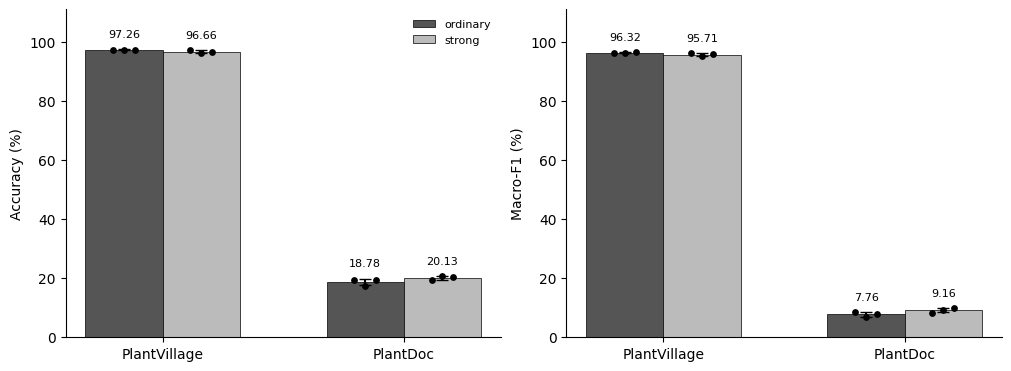

In [15]:
fig,axes=plt.subplots(1,2,figsize=(10,3.6),layout='constrained')
s=summary.set_index(['condition','split'])
for ax,metric,title in zip(axes,['accuracy','macro_f1'],['Accuracy','Macro-F1']):
    for j,(condition,color) in enumerate([('ordinary','#555555'),('strong','#BBBBBB')]):
        means=[100*s.loc[(condition,t),metric+'_mean'] for t in ['pv_test','pd_test']]
        stds=[100*s.loc[(condition,t),metric+'_std'] for t in ['pv_test','pd_test']]
        positions=np.arange(2)+(j-.5)*.32
        bars=ax.bar(positions,means,.32,yerr=stds,capsize=4,color=color,edgecolor='black',linewidth=.5,label=condition)
        ax.bar_label(bars,fmt='%.2f',padding=7,fontsize=8)
        for pos,split in zip(positions,['pv_test','pd_test']):
            values=100*metrics.loc[metrics['condition'].eq(condition)&metrics['split'].eq(split)].sort_values('seed')[metric].to_numpy()
            ax.scatter(pos+np.array([-.045,0,.045]),values,c='black',s=15,zorder=3)
    ax.set(xticks=[0,1],xticklabels=['PlantVillage','PlantDoc'],ylim=(0,111),ylabel=title+' (%)')
axes[0].legend(frameon=False,fontsize=8)
plt.show()


### 配对种子差值与条件 bootstrap

先计算每个种子内 strong − ordinary 的差值，全部展示。三个种子的均值/标准差描述训练波动。另对每个已拟合模型对做 2,000 次类别内配对 bootstrap，描述固定样本的不确定性；不能把它当成训练波动，也不能把三组重复预测当作三倍独立测试图片。


In [16]:
delta_rows=[];interval_rows=[]
for seed in SEEDS:
    for split in ['pv_test','pd_test']:
        m=metrics.loc[metrics['seed'].eq(seed)&metrics['split'].eq(split)].set_index('condition')
        delta_rows.append(dict(seed=seed,split=split,
            accuracy_delta_pp=100*(m.loc['strong','accuracy']-m.loc['ordinary','accuracy']),
            macro_f1_delta_pp=100*(m.loc['strong','macro_f1']-m.loc['ordinary','macro_f1'])))
    paired=predictions.loc[predictions['seed'].eq(seed)&predictions['split'].eq('pd_test')].pivot(
        index=['path','y_true'],columns='condition',values='y_pred').reset_index()
    truth=paired['y_true'].to_numpy();a=paired['ordinary'].to_numpy();b=paired['strong'].to_numpy()
    strata=[np.flatnonzero(truth==k) for k in class_ids];rng=np.random.default_rng(664);boot=[]
    for _ in range(2000):
        ix=np.concatenate([rng.choice(group,len(group),replace=True) for group in strata])
        def score(pred):
            cm=np.bincount(9*truth[ix]+pred[ix],minlength=81).reshape(9,9)
            return np.array([np.trace(cm)/len(ix),np.mean(2*cm.diagonal()/(cm.sum(0)+cm.sum(1)))])
        boot.append(score(b)-score(a))
    limits=np.quantile(boot,[.025,.975],axis=0)
    original=pd.read_csv(FRESH/f'seed_{seed}'/'paired_field_bootstrap.csv',index_col=0)
    np.testing.assert_allclose(limits,original.to_numpy(),atol=1e-12,rtol=0)
    interval_rows.append(dict(seed=seed,accuracy_p025_pp=100*limits[0,0],accuracy_p975_pp=100*limits[1,0],
        macro_f1_p025_pp=100*limits[0,1],macro_f1_p975_pp=100*limits[1,1]))
deltas=pd.DataFrame(delta_rows)
display(deltas.round(2))
display(deltas.groupby('split')[['accuracy_delta_pp','macro_f1_delta_pp']].agg(['mean','std']).round(2))
display(pd.DataFrame(interval_rows).round(2))


,seed,split,accuracy_delta_pp,macro_f1_delta_pp
0,664,pv_test,-0.06,-0.19
1,664,pd_test,-0.27,-0.06
2,665,pv_test,-0.93,-0.94
3,665,pd_test,3.10,2.47
4,666,pv_test,-0.84,-0.69
5,666,pd_test,1.21,1.79


accuracy_delta_pp       macro_f1_delta_pp      
                     mean   std              mean   std
split                                                  
pd_test              1.35  1.69              1.40  1.31
pv_test             -0.61  0.48             -0.61  0.38

,seed,accuracy_p025_pp,accuracy_p975_pp,macro_f1_p025_pp,macro_f1_p975_pp
0,664,-2.16,1.75,-1.55,1.51
1,665,1.21,4.99,0.95,3.98
2,666,-0.54,3.10,0.53,3.18


## 7. 逐类差距与固定种子的混淆矩阵

种子 664 在查看新增田间结果之前就固定为展示用模型，未按田间分数挑选。全体种子结果都用于主要比较。下面的逐类表给出三种子平均召回及 clean − field 差距；完整逐种子 F1 与标准差也保存在 CSV 中。


condition        ordinary                 strong                
split              gap_pp pd_test pv_test gap_pp pd_test pv_test
category                                                        
Healthy              98.7     0.5    99.2   98.5     0.5    99.0
Early blight         52.0    34.8    86.8   58.0    26.5    84.5
Bacterial spot       97.3     0.0    97.3   96.1     0.6    96.7
Late blight          11.4    85.9    97.3   10.4    86.5    96.9
Mosaic virus         98.0     0.0    98.0   98.5     0.0    98.5
Yellow leaf curl     97.8     1.3    99.2   96.3     1.3    97.7
Leaf mold            95.4     0.7    96.1   93.5     0.7    94.2
Septoria             87.6     7.6    95.3   80.1    18.3    98.4
Spider mites         98.1     0.0    98.1   97.7     0.0    97.7

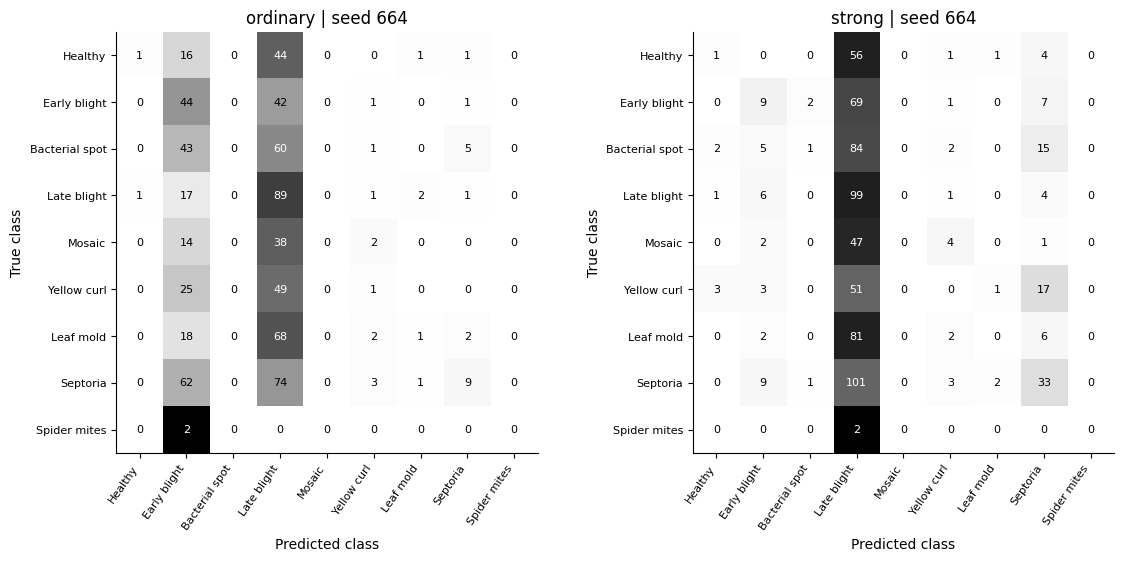

In [17]:
per_class=pd.DataFrame(class_rows)
class_means=per_class.groupby(['condition','split','category'])[['recall','f1']].mean().reset_index()
recall_table=100*class_means.pivot(index='category',columns=['condition','split'],values='recall').reindex(class_names)
for condition in ['ordinary','strong']:
    recall_table[(condition,'gap_pp')]=recall_table[(condition,'pv_test')]-recall_table[(condition,'pd_test')]
display(recall_table.sort_index(axis=1).round(1))
short_names=['Healthy','Early blight','Bacterial spot','Late blight','Mosaic','Yellow curl','Leaf mold','Septoria','Spider mites']
fig,axes=plt.subplots(1,2,figsize=(11.5,5.5),layout='constrained')
for ax,condition in zip(axes,['ordinary','strong']):
    g=predictions.loc[predictions['seed'].eq(664)&predictions['condition'].eq(condition)&predictions['split'].eq('pd_test')]
    cm=confusion_matrix(g['y_true'],g['y_pred'],labels=class_ids);normalized=cm/cm.sum(1,keepdims=True)
    ax.imshow(normalized,vmin=0,vmax=1,cmap='Greys')
    for i in class_ids:
        for j in class_ids:ax.text(j,i,str(cm[i,j]),ha='center',va='center',fontsize=8,color='white' if normalized[i,j]>.5 else 'black')
    ax.set(xticks=class_ids,yticks=class_ids,xticklabels=short_names,yticklabels=short_names,
        xlabel='Predicted class',ylabel='True class',title=condition+' | seed 664')
    plt.setp(ax.get_xticklabels(),rotation=55,ha='right',fontsize=8);plt.setp(ax.get_yticklabels(),fontsize=8)
plt.show()


## 8. 基线与置信度诊断

恒定类别根据源训练标签的多数类确定；不用田间标签选择。高 softmax 分数不等于可靠的田间诊断概率。三种子不会增加稀有类别独立样本的数量。


In [18]:
majority=int(manifest.loc[manifest['split'].eq('pv_train'),'label'].astype(int).value_counts().idxmax())
baselines=[]
for split in ['pv_test','pd_test']:
    y=manifest.loc[manifest['split'].eq(split),'label'].astype(int).to_numpy();p=np.full(len(y),majority)
    baselines.append(dict(split=split,class_name=class_names[majority],accuracy=accuracy_score(y,p),
        macro_f1=f1_score(y,p,labels=class_ids,average='macro',zero_division=0)))
display(pd.DataFrame(baselines).style.format({'accuracy':'{:.2%}','macro_f1':'{:.2%}'}))
confidence=[]
for (seed,condition),g in predictions.loc[predictions['split'].eq('pd_test')].groupby(['seed','condition']):
    high=g.loc[g['confidence'].ge(.9)]
    confidence.append(dict(seed=seed,condition=condition,n_high=len(high),correct=int(high['y_true'].eq(high['y_pred']).sum()),
        accuracy=high['y_true'].eq(high['y_pred']).mean()))
display(pd.DataFrame(confidence).style.format({'accuracy':'{:.2%}'}))


,split,class_name,accuracy,macro_f1
0,pv_test,Yellow leaf curl,32.83%,5.49%
1,pd_test,Yellow leaf curl,10.11%,2.04%


,seed,condition,n_high,correct,accuracy
0,664,ordinary,501,111,22.16%
1,664,strong,519,111,21.39%
2,665,ordinary,633,114,18.01%
3,665,strong,501,105,20.96%
4,666,ordinary,554,114,20.58%
5,666,strong,375,98,26.13%


## 9. 新权重的实际离线推理

两张固定示例均标注为 early blight，在原实验分析时选取。本次不根据新增表现更换案例。下面加载新训练 seed-664 的权重并实际推理，核对原始图片哈希和对应的完整测试预测。


,condition,epoch,parameters
0,ordinary,8,1527081
1,strong,8,1527081


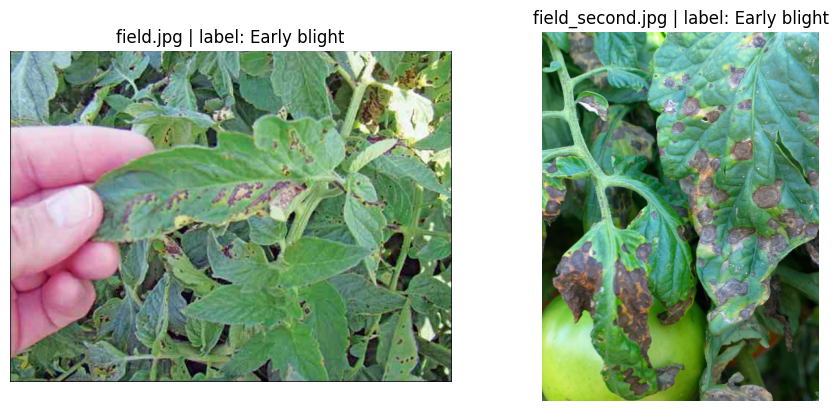

,image,condition,rank,predicted_class,softmax
0,field.jpg,ordinary,1,Late blight,68.23%
1,field.jpg,ordinary,2,Early blight,31.63%
2,field.jpg,ordinary,3,Yellow leaf curl,0.13%
3,field.jpg,strong,1,Late blight,91.08%
4,field.jpg,strong,2,Early blight,8.16%
5,field.jpg,strong,3,Septoria,0.26%
6,field_second.jpg,ordinary,1,Early blight,98.75%
7,field_second.jpg,ordinary,2,Late blight,1.25%
8,field_second.jpg,ordinary,3,Leaf mold,0.00%
9,field_second.jpg,strong,1,Late blight,94.03%


PASS: example hashes and top predictions match the saved test evidence.


In [19]:
models = {}
checkpoint_rows = []
for condition in ['ordinary','strong']:
    checkpoint = torch.load(FRESH / 'seed_664' / f'{condition}.pt', map_location='cpu', weights_only=True)
    assert checkpoint['labels'] == class_names and checkpoint['size'] == SIZE
    expected_epoch = int(training_audit.loc[training_audit['seed'].eq(664) & training_audit['condition'].eq(condition), 'selected_epoch'].iloc[0])
    assert checkpoint['epoch'] == expected_epoch
    net = model(False)
    net.load_state_dict(checkpoint['model'])
    net.eval()
    models[condition] = net
    checkpoint_rows.append(dict(condition=condition, epoch=checkpoint['epoch'],
                                parameters=sum(p.numel() for p in net.parameters())))
display(pd.DataFrame(checkpoint_rows))

credits = pd.read_csv(PROJECT / 'examples/credits.csv')
demo_rows = []
fig, axes = plt.subplots(1, 2, figsize=(9,4), layout='constrained')
for ax, filename in zip(axes, ['field.jpg','field_second.jpg']):
    photo = PROJECT / 'examples' / filename
    with Image.open(photo) as im:
        rgb = ImageOps.exif_transpose(im).convert('RGB')
        ax.imshow(rgb)
        x = transforms('ordinary',False)(rgb).unsqueeze(0)
    ax.set_title(filename+' | label: Early blight')
    ax.axis('off')
    original_path = credits.loc[credits['use'].eq(filename), 'path'].iloc[0]
    original_hash = manifest.loc[manifest['path'].eq(original_path), 'sha256'].iloc[0]
    assert hashlib.sha256(photo.read_bytes()).hexdigest() == original_hash
    for condition, net in models.items():
        with torch.inference_mode():
            features = net.features[:-2](x).half().float()
            probabilities = head(net, features).softmax(1)[0]
        index = int(probabilities.argmax())
        old = predictions.loc[predictions['seed'].eq(664) & predictions['path'].eq(original_path) & predictions['condition'].eq(condition)].iloc[0]
        assert index == int(old['y_pred'])
        for rank, k in enumerate(probabilities.argsort(descending=True)[:3].tolist(), start=1):
            demo_rows.append(dict(image=filename, condition=condition, rank=rank,
                                 predicted_class=class_names[k], softmax=float(probabilities[k])))
plt.show()
display(pd.DataFrame(demo_rows).style.format({'softmax':'{:.2%}'}))
print('PASS: example hashes and top predictions match the saved test evidence.')


## 10. 原始结果作为参考

原两视图、单种子结果保留，不冒充本次新训练。旧实验使用 CPU/PyTorch 2.5.1；新实验使用 GPU/PyTorch 2.7.1，随机数实现和数据流也改变。因此新旧绝对分数之差不是对“刷新视图”这一单一因素的纯消融；受控比较是新协议内的两种增强。


In [20]:
legacy=pd.read_csv(RESULTS/'overall.csv')
display(legacy.style.format({'accuracy':'{:.2%}','macro_f1':'{:.2%}'}))
print('Legacy checkpoint replay record:')
display(pd.DataFrame([json.loads((RESULTS/'replay_verification.json').read_text())]))
if RUN_FULL_REPLAY:
    from evaluate import evaluate
    for seed in SEEDS:
        evaluate(DATA_DIR,FRESH/f'seed_{seed}',SCRATCH/f'replay_{seed}',DEVICE,compare=True)
else:
    print('Full raw-image replay skipped in this Notebook execution.')


,condition,split,n,correct,accuracy,macro_f1
0,ordinary,pd_test,742,145,19.54%,8.67%
1,ordinary,pv_test,3351,3259,97.25%,96.51%
2,strong,pd_test,742,139,18.73%,8.57%
3,strong,pv_test,3351,3220,96.09%,94.96%


Legacy checkpoint replay record:


,status,raw_image_hashes_checked,prediction_rows,device,torch,top1_mismatches,max_probability_delta
0,PASS,4093,8186,cpu,2.5.1+cpu,0,0.000259


Full raw-image replay skipped in this Notebook execution.


## 11. 独立证据校验和研究结论

用标准库校验器复核三个新种子的全部保存证据；检查测试前锁定的 checkpoint 哈希仍与现在的文件相同。训练记录证明本次新任务确实完成六组训练，不能用快速 Notebook 重算时长替代训练时长。


In [21]:
from verify import audit
locked=json.loads((FRESH/'selection_locked.json').read_text(encoding='utf-8'))
for seed in SEEDS:
    result=audit(FRESH/f'seed_{seed}')
    assert result['status']=='PASS'
    for condition in ['ordinary','strong']:
        digest=hashlib.sha256((FRESH/f'seed_{seed}'/f'{condition}.pt').read_bytes()).hexdigest()
        assert digest==locked['checkpoint_sha256'][f'{seed}/{condition}']
aggregate=json.loads((FRESH/'aggregate_verification.json').read_text(encoding='utf-8'))
assert aggregate['status']=='PASS'
display(pd.DataFrame([aggregate]))
interpretation=json.loads((FRESH/'interpretation.json').read_text(encoding='utf-8'))
display(Markdown('**Observed result:** '+interpretation['conclusion']))
for sentence in interpretation['field_error_summary']:print(sentence)
print('PASS: all three seed audits and six locked checkpoints verified.')
replay_records=[]
for seed in SEEDS:
    r=json.loads((FRESH/f'seed_{seed}'/'replay_verification.json').read_text(encoding='utf-8'))
    assert r['status']=='PASS' and r['top1_mismatches']==0
    replay_records.append(dict(seed=seed,raw_images=r['raw_image_hashes_checked'],
        predictions=r['prediction_rows'],top1_mismatches=r['top1_mismatches'],max_probability_delta=r['max_probability_delta']))
print('Independent raw-image replay records (already performed separately, not repeated by default):')
display(pd.DataFrame(replay_records))


,status,seeds,trained_models,unique_completed_epochs,optimizer_steps,total_image_presentations,identical_initialization_within_seed,identical_sample_order_within_seed,all_six_checkpoints_locked_before_test_predictions,original_split_preserved,all_per_seed_artifact_audits_passed,interpretation
0,PASS,"[664, 665, 666]",6,48,6048,577728,True,True,True,True,True,Mean and sample SD describe three fitted seeds...


**Observed result:** Strong augmentation improved both field metrics on average, but the paired improvements were not consistent across all three seeds.

Ordinary training most often predicted late blight, assigning that label to 540.0 of 742 field images on average (SD 85.8); its true support was 111.
Strong training most often predicted late blight, assigning that label to 543.7 of 742 field images on average (SD 56.3); its true support was 111.
The largest signed mean class-recall change was +10.7 pp for septoria, and the smallest was -8.3 pp for early blight.
PASS: all three seed audits and six locked checkpoints verified.
Independent raw-image replay records (already performed separately, not repeated by default):


,seed,raw_images,predictions,top1_mismatches,max_probability_delta
0,664,4093,8186,0,0.000309
1,665,4093,8186,0,0.000311
2,666,4093,8186,0,0.000184


**已解决的实验弱点**：完成实际新增训练；强增强每轮重新采样；从一个种子扩展为三个配对种子；记录每次结果和波动，不挑选最好田间分数。

**仍然存在的局限**：验证集缺少 mosaic 类；4,280 张训练图、1,060 张干净测试图缺少叶片 ID；字节去重不能排除全部近重复；田间 spider mites 只有两张相关图片；三个种子仍很少。

新增研究是在看过原始田间结果后设计的探索性后续实验。虽然田间标签未用于训练或 checkpoint 选择，该集合已不是从未检查过的全新确认性测试。更强的下一步是独立标注的田间集合和预先固定的目标域开发/测试隔离，而不是继续按这份测试集的分数选择方法。

### 来源

- Mohanty, Hughes & Salathé (2016), [PlantVillage paper](https://doi.org/10.3389/fpls.2016.01419), [dataset and leaf metadata](https://github.com/spMohanty/PlantVillage-Dataset), [official grouped splits](https://huggingface.co/datasets/mohanty/PlantVillage/tree/main/splits).
- Singh et al. (2020), [PlantDoc paper](https://doi.org/10.1145/3371158.3371196), [cropped classification repository](https://github.com/pratikkayal/PlantDoc-Dataset), CC BY 4.0. Example credits: `project/examples/credits.csv`.
- Howard et al. (2019), [Searching for MobileNetV3](https://arxiv.org/abs/1905.02244).
